[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/17_hypercoast_tanager_enmap.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🌐 HyperCoast: Tanager and EnMAP side by side — and on to QGIS
### Space Academy 2026 · Hyperspectral course · Week 2 — Hyperspectral data in HyperCoast and QGIS (Practical)

So far every notebook has used `hsi_utils`, a small module written for this course. That is deliberate: you can
read all of it. But in a project you should also know the community tools. **HyperCoast**
([hypercoast.org](https://hypercoast.org), Liu & Wu 2024) reads a dozen imaging spectrometers — including
**Tanager** and **EnMAP** — with one API, plots spectra interactively on a map, renders 3-D cubes, and has a
**QGIS plugin** so the same data opens in a desktop GIS.

This session is the bridge between Python and QGIS: read both sensors, compare them, then export data that a
GIS can use properly. The QGIS half of the session is the step-by-step lab in
[`qgis_lab_hyperspectral.md`](qgis_lab_hyperspectral.md).

**What you will learn**
- Read Tanager and EnMAP with HyperCoast, and when to prefer it over `hsi_utils`
- Search the Tanager archive and pull spectra at a coordinate rather than a pixel index
- Compare the same target seen by two sensors with different spectral sampling
- Render an interactive map, a spectral plot and a 3-D cube
- Export a cube so **QGIS and the EnMAP-Box** show real wavelengths, not band numbers

**Prerequisites:** notebooks `10` (spectral signatures) and `11` (preprocessing).
**Data:** the Tanager course scenes, plus an **EnMAP L2A subset over Groningen** shipped in `data/enmap/`
(250 × 250 px, 224 bands; the full 249 MB scene can be fetched with `tools/get_enmap_example.py`).

> **Install:** `pip install hypercoast` (needs **Python ≥ 3.11**, which is stricter than the rest of the course).
> Interactive maps need Jupyter widgets; in Colab run `hypercoast.Map()` in its own cell.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q hypercoast
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

try:
    import hypercoast
    HAVE_HC = True
    print("hypercoast", hypercoast.__version__, "· python", sys.version.split()[0])
except ImportError:
    HAVE_HC = False
    print("hypercoast is not installed — run: pip install hypercoast (needs Python >= 3.11)")

hypercoast 0.27.0 · python 3.13.13


## 1. Two libraries, two jobs

| | `hsi_utils` (this course) | `hypercoast` |
|---|---|---|
| Scope | Tanager, tuned for teaching | EMIT, PACE, AVIRIS, NEON, DESIS, PRISMA, **EnMAP**, **Tanager**, Wyvern |
| Reading | lazy: windows, strides, chosen bands | whole cube into an `xarray.Dataset` (or selected bands) |
| Masks | QA masks applied for you | raw data; you apply masks |
| Visualisation | matplotlib | interactive `leafmap` map, click-to-plot spectra, 3-D cubes |
| Elsewhere | — | **QGIS plugin** with the same readers |

Neither replaces the other. Use `hsi_utils` when you need control over memory and masking, and HyperCoast when you
want to explore interactively or to touch another sensor without writing a new reader.

**The memory trap first.** `read_tanager()` loads the *whole* cube as float64 and keeps a `toa_radiance` alias of
the same array, so a Tanager scene becomes ~4 GB in RAM. Always pass `bands=` (it reads only those bands from
disk) or work on a subset.

In [2]:
SCENE_ID = "20250223_165546_32_4001"          # Usulután, El Salvador — mangroves and estuary
path = hu.get_scene_path(SCENE_ID)
print(path.name)

scene = hu.get_scene(SCENE_ID)                 # hsi_utils view, for comparison
every_4th = np.where(scene.good_bands)[0][::4] # 88 good bands is plenty for exploration
print(f"reading {len(every_4th)} of {scene.shape[0]} bands with hypercoast")

ds = hypercoast.read_tanager(path, bands=every_4th)
print(ds)

20250223_165546_32_4001_ortho_sr_hdf5.h5
reading 88 of 426 bands with hypercoast


<xarray.Dataset> Size: 732MB
Dimensions:              (wavelength: 88, y: 655, x: 785)
Coordinates:
  * wavelength           (wavelength) float64 704B 401.3 421.2 ... 2.435e+03
    fwhm                 (wavelength) float64 704B 5.55 5.66 5.77 ... 5.28 5.26
    latitude             (y, x) float64 4MB 13.32 13.32 13.32 ... 13.14 13.14
    longitude            (y, x) float64 4MB -88.56 -88.56 ... -88.35 -88.35
Dimensions without coordinates: y, x
Data variables:
    surface_reflectance  (wavelength, y, x) float64 362MB nan nan ... nan nan
    toa_radiance         (wavelength, y, x) float64 362MB nan nan ... nan nan
Attributes:
    source:     Planet Tanager HDF5
    product:    ortho_sr
    stac_item:  
    data_var:   surface_reflectance


`read_tanager` returns an `xarray.Dataset` with `wavelength`, `fwhm`, and **`latitude`/`longitude` arrays** for
every pixel. That last part is the practical difference from `hsi_utils`: you can ask for a spectrum at a
coordinate without converting to row/column yourself.

In [3]:
mem_gb = ds.nbytes / 1e9
print(f"in memory: {mem_gb:.2f} GB for {ds.sizes['wavelength']} bands "
      f"({ds.sizes['y']}×{ds.sizes['x']} px, float64, two variables)")
print(f"all 426 bands would be ~{mem_gb * 426 / ds.sizes['wavelength']:.1f} GB")
win = (150, 400, 150, 400)                     # a 250 x 250 window: the usual working unit
cube, wl = scene.read_cube(win, bands=every_4th)
scale = (scene.shape[1] * scene.shape[2]) / (cube.shape[1] * cube.shape[2])
print("\nhsi_utils (float32, one variable, QA-masked):")
print(f"  {cube.nbytes / 1e6:6.0f} MB for the 250x250 window actually needed")
print(f"  {cube.nbytes * scale / 1e9:6.2f} GB if you insisted on the whole scene at these bands")

in memory: 0.73 GB for 88 bands (655×785 px, float64, two variables)
all 426 bands would be ~3.5 GB



hsi_utils (float32, one variable, QA-masked):
      22 MB for the 250x250 window actually needed
    0.18 GB if you insisted on the whole scene at these bands


## 2. Finding scenes: HyperCoast's STAC search

`search_tanager()` and `tanager_footprints()` crawl Planet's public catalogue live (no account needed). That is
the same catalogue `16_scene_finder.ipynb` indexed offline — use whichever fits: live search for a fresh look,
the cached index for a classroom with poor connectivity.

In [4]:
UAE_BBOX = [51.0, 22.5, 56.5, 26.5]     # west, south, east, north

try:
    gdf = hypercoast.tanager_footprints(bbox=UAE_BBOX, return_items=False)
    print(f"{len(gdf)} Tanager scenes over the UAE bounding box")
    print(gdf[["id", "datetime"]].head(8).to_string(index=False))
except Exception as err:                 # offline classroom, proxy, or API change
    print("live search unavailable:", type(err).__name__, err)
    idx = hu.load_catalog_index()
    sel = idx.cx[UAE_BBOX[0]:UAE_BBOX[2], UAE_BBOX[1]:UAE_BBOX[3]]
    print(f"offline index instead: {len(sel)} scenes")
    print(sel[["id", "datetime", "location"]].head(8).to_string(index=False))

1 Tanager scenes over the UAE bounding box
                     id             datetime
20250511_074311_00_4001 2025-05-11T07:43:11Z


## 3. Spectra at a coordinate

`extract_tanager(ds, latitude, longitude, delta=...)` averages the pixels within `delta` degrees of a point.
Here are three targets in the El Salvador scene: dense mangrove, open estuary water, and a sugar-cane field.

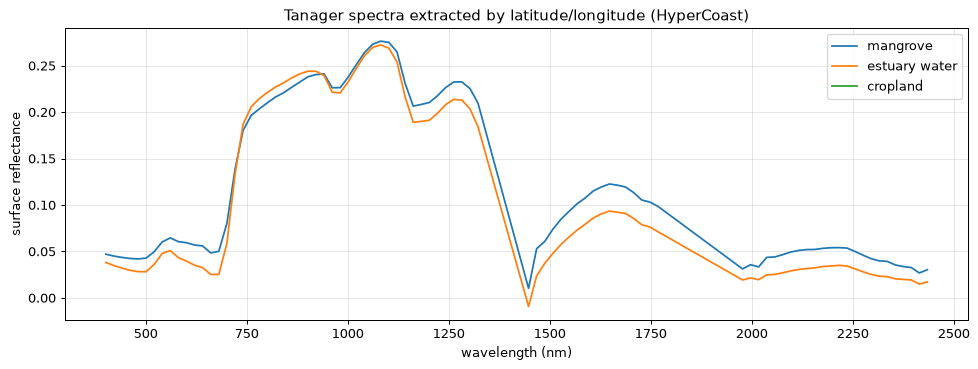

In [5]:
TARGETS = {                                    # lat, lon picked from the scene
    "mangrove":      (13.253, -88.505),
    "estuary water": (13.230, -88.470),
    "cropland":      (13.320, -88.520),
}

fig, ax = plt.subplots(figsize=(11, 4.2))
for name, (lat, lon) in TARGETS.items():
    spec = hypercoast.extract_tanager(ds, latitude=lat, longitude=lon, delta=0.004)
    ax.plot(spec.wavelength, np.asarray(spec).astype(float), lw=1.4, label=name)
ax.set(xlabel="wavelength (nm)", ylabel="surface reflectance",
       title="Tanager spectra extracted by latitude/longitude (HyperCoast)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 4. The interactive map

`hypercoast.Map()` is a `leafmap.Map` subclass. `add_tanager()` puts a band composite on the map, and the
spectral widget plots the spectrum of whatever pixel you click — the fastest way to explore an unfamiliar scene.

The cell below builds the map. In a live Jupyter session you get a slippy map with a spectral panel; in a
statically executed notebook (like this one, when it ships) you see only the widget placeholder, so the next
cell reproduces the same composite with matplotlib.

Map(center=[13.227773500000001, -88.4558265], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom…

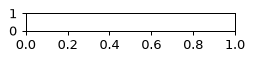

In [6]:
m = hypercoast.Map(center=[13.25, -88.5], zoom=11)
m.add_tanager(ds, wavelengths=[640, 550, 460], vmin=0.0, vmax=0.3, layer_name="Tanager RGB")
m.add_colormap(cmap="terrain", label="elevation-free basemap reference", visible=False)
m  # click a pixel to plot its spectrum (live Jupyter only)

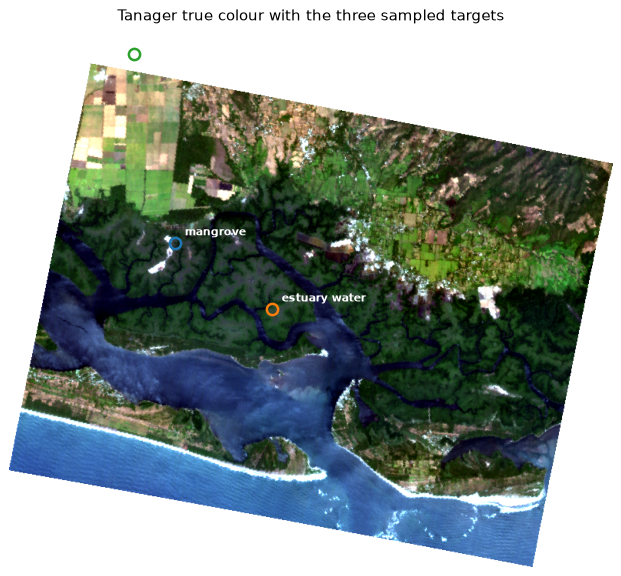

In [7]:
# Static equivalent, so this notebook is useful when read rather than run
rgb = np.dstack([np.asarray(ds["surface_reflectance"].sel(wavelength=w, method="nearest"))
                 for w in (640, 550, 460)])
rgb = hu.stretch(rgb, (2, 98))
rgb[np.isnan(rgb)] = 1.0

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(rgb)
for name, (lat, lon) in TARGETS.items():
    r, c = scene.lonlat_to_rowcol(lon, lat)
    ax.plot(c[0], r[0], "o", ms=9, mfc="none", mew=2)
    ax.annotate(name, (c[0], r[0]), xytext=(8, 6), textcoords="offset points",
                color="white", fontsize=9, weight="bold")
ax.set_title("Tanager true colour with the three sampled targets"); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. EnMAP

EnMAP (DLR) has flown since 2022: 224 bands, 420–2450 nm, 30 m — the closest public analogue to Tanager, and a
useful sanity check on anything you conclude from a single sensor.

`data/enmap/` holds a 250 × 250 px subset of the official **Groningen** example scene (Netherlands, 10 Aug 2022)
together with its `METADATA.XML`. Two practical notes, both of which you will hit with real EnMAP products:

1. Official EnMAP L2A ships as **ENVI BSQ + .hdr**, not GeoTIFF. `read_enmap()` expects a GeoTIFF, and on a BSQ it
   fails with `the new name 'wavelength' conflicts` (the ENVI header already defines a `wavelength` coordinate).
   Convert the cube to GeoTIFF first — `tools/get_enmap_example.py` does exactly that.
2. `read_enmap()` finds wavelengths in the GeoTIFF only if they sit in the *dataset* metadata; band-level or
   ENVI-domain tags are missed. Keeping `*METADATA.XML` **in the same folder** is the reliable route, because the
   reader falls back to parsing it. (The documented `wavelengths=` argument raises `UnboundLocalError` in 0.27.0.)

In [8]:
enmap_dir = hu.DATA_DIR / "enmap"
enmap_tif = next(enmap_dir.glob("*.tif"), None)

if enmap_tif is None:
    print("No EnMAP subset found. Run:  python tools/get_enmap_example.py")
else:
    en = hypercoast.read_enmap(enmap_tif)          # METADATA.XML next to it supplies the wavelengths
    print(f"{enmap_tif.name}: {dict(en.sizes)}")
    print(f"wavelengths {float(en.wavelength[0]):.0f}–{float(en.wavelength[-1]):.0f} nm, "
          f"{en.sizes['wavelength']} bands")

enmap_groningen_subset.tif: {'x': 250, 'y': 250, 'wavelength': 224}
wavelengths 418–2446 nm, 224 bands


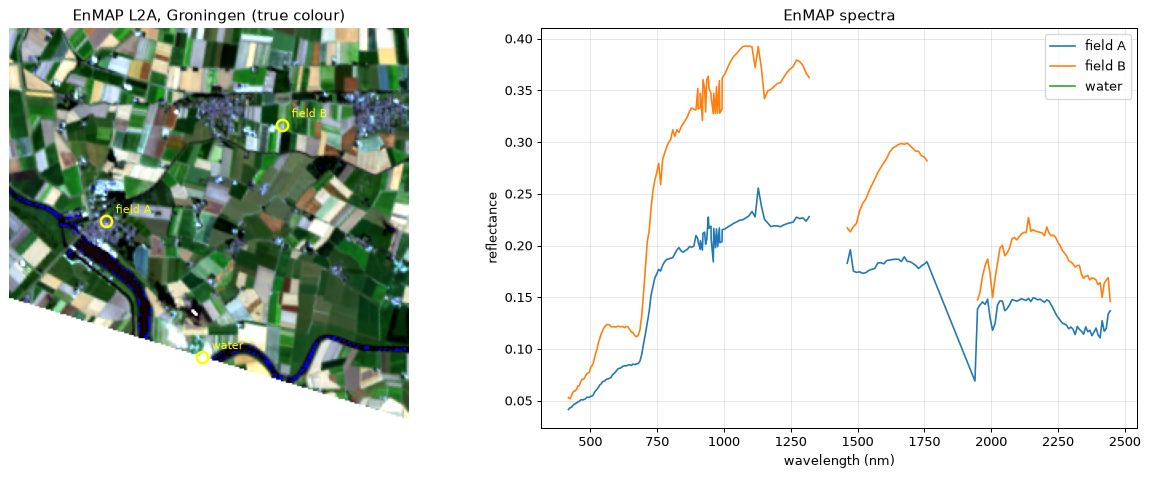

In [9]:
en_refl = en["reflectance"] / 10000.0              # EnMAP L2A is stored as int16 x 10000
rgb_en = np.dstack([np.asarray(en_refl.sel(wavelength=w, method="nearest")) for w in (640, 550, 460)])
rgb_en = hu.stretch(np.where(rgb_en > 0, rgb_en, np.nan), (2, 98))
rgb_en[np.isnan(rgb_en)] = 1.0

EN_TARGETS = {"field A": (120, 60), "field B": (60, 170), "water": (205, 120)}   # row, col

fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
ax[0].imshow(rgb_en); ax[0].set_title("EnMAP L2A, Groningen (true colour)"); ax[0].axis("off")
for name, (r, c) in EN_TARGETS.items():
    ax[0].plot(c, r, "o", ms=9, mfc="none", mew=2, color="yellow")
    ax[0].annotate(name, (c, r), xytext=(8, 6), textcoords="offset points", color="yellow", fontsize=9)
    spec = np.asarray(en_refl[r, c, :]).astype(float)
    spec[spec <= 0] = np.nan
    ax[1].plot(np.asarray(en.wavelength), spec, lw=1.3, label=name)
ax[1].set(xlabel="wavelength (nm)", ylabel="reflectance", title="EnMAP spectra")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Tanager vs EnMAP on the same target

The two sensors sample the spectrum differently: Tanager ~5 nm across 426 bands, EnMAP ~6.5 nm (VNIR) to ~10 nm
(SWIR) across 224. To compare like with like, resample the Tanager spectrum onto EnMAP's band centres and FWHM
(`hu.resample_to_sensor`) — the same trick notebook 10 used for Sentinel-2.

The scenes are different places, so this compares *sampling*, not the same field.

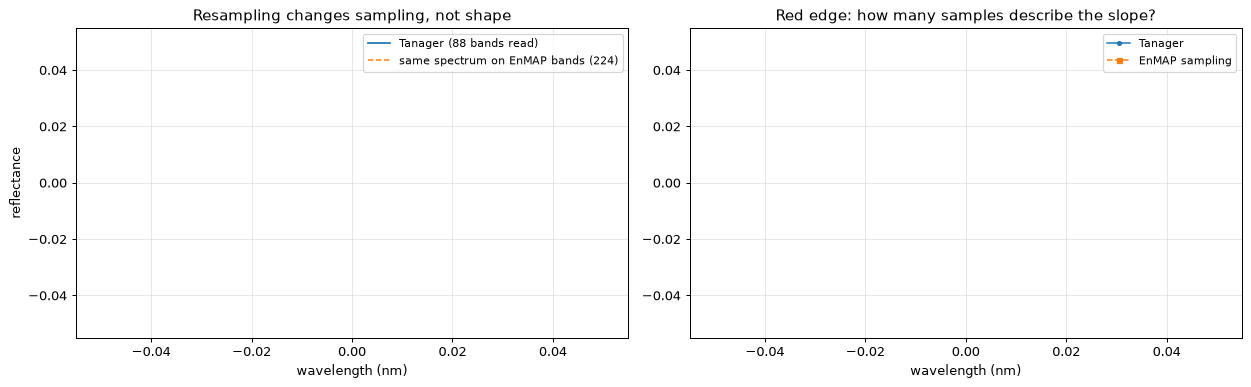

samples across the red edge (670–780 nm): Tanager 5 (of 426 bands), EnMAP 16


In [10]:
veg_tanager = hypercoast.extract_tanager(ds, latitude=TARGETS["cropland"][0],
                                         longitude=TARGETS["cropland"][1], delta=0.004)
wl_t = np.asarray(veg_tanager.wavelength, dtype=float)
sp_t = np.asarray(veg_tanager, dtype=float)

wl_e = np.asarray(en.wavelength, dtype=float)
fwhm_e = np.gradient(wl_e)                                  # nominal EnMAP band widths
sp_t_on_enmap = hu.resample_to_sensor(wl_t, sp_t, wl_e, fwhm_e)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].plot(wl_t, sp_t, lw=1.4, label=f"Tanager ({len(wl_t)} bands read)")
ax[0].plot(wl_e, sp_t_on_enmap, lw=1.2, ls="--", label=f"same spectrum on EnMAP bands ({len(wl_e)})")
ax[0].set(xlabel="wavelength (nm)", ylabel="reflectance", title="Resampling changes sampling, not shape")
ax[0].legend(fontsize=9); ax[0].grid(alpha=.3)

red_edge = (wl_t > 670) & (wl_t < 780)
red_edge_e = (wl_e > 670) & (wl_e < 780)
ax[1].plot(wl_t[red_edge], sp_t[red_edge], "o-", ms=3, lw=1.2, label="Tanager")
ax[1].plot(wl_e[red_edge_e], sp_t_on_enmap[red_edge_e], "s--", ms=4, lw=1.2, label="EnMAP sampling")
ax[1].set(xlabel="wavelength (nm)", title="Red edge: how many samples describe the slope?")
ax[1].legend(fontsize=9); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"samples across the red edge (670–780 nm): Tanager {red_edge.sum()} (of 426 bands), "
      f"EnMAP {red_edge_e.sum()}")

## 7. Spectral tools that come with HyperCoast

`hypercoast.spectral_angle` and `hypercoast.continuum_remove` are the same operations you implemented in
notebooks 10 and 14 — useful for a quick check without writing code.

spectral angle to mangrove — mangrove      :   0.0°
spectral angle to mangrove — estuary water :   6.7°
spectral angle to mangrove — cropland      :   nan°


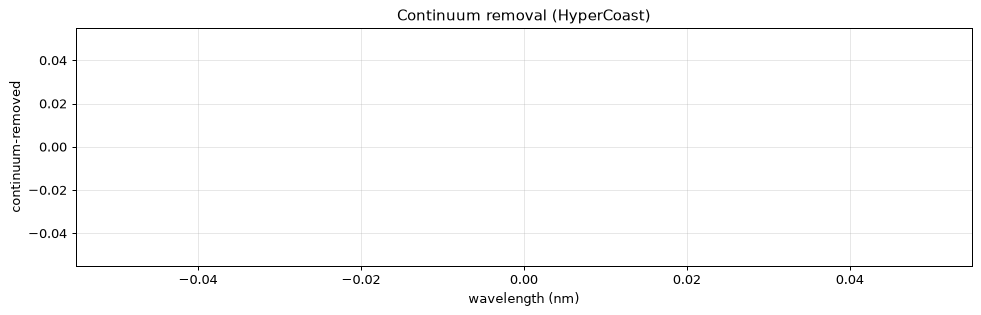

In [11]:
ref = np.asarray(hypercoast.extract_tanager(ds, *TARGETS["mangrove"], delta=0.004), dtype=float)
for name, (lat, lon) in TARGETS.items():
    spec = np.asarray(hypercoast.extract_tanager(ds, latitude=lat, longitude=lon, delta=0.004), dtype=float)
    ok = np.isfinite(spec) & np.isfinite(ref)
    ang = hypercoast.spectral_angle(spec[ok], ref[ok])
    print(f"spectral angle to mangrove — {name:14s}: {np.degrees(ang):5.1f}°")

veg = np.asarray(hypercoast.extract_tanager(ds, *TARGETS["cropland"], delta=0.004), dtype=float)
cr = hypercoast.continuum_remove(veg, wl_t)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(wl_t, cr, lw=1.3)
ax.set(xlabel="wavelength (nm)", ylabel="continuum-removed", title="Continuum removal (HyperCoast)")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 8. The 3-D cube

`image_cube()` renders the cube as a PyVista volume: the top face is an RGB composite and the sides show how
reflectance varies with wavelength. It needs a desktop OpenGL context, so it is off by default here — switch
`SHOW_CUBE = True` when you run this notebook yourself.

In [12]:
SHOW_CUBE = False        # set True in a desktop Jupyter session (needs pyvista + a display)

if SHOW_CUBE:
    p = hypercoast.image_cube(en.rename({"reflectance": "reflectance"}),
                              variable="reflectance", cmap="jet", clim=(0, 3000),
                              rgb_wavelengths=[640, 550, 460], title="EnMAP cube")
    p.show()
else:
    print("3-D cube skipped (SHOW_CUBE = False).")
    print("In a live session it opens an interactive window you can rotate and slice.")

3-D cube skipped (SHOW_CUBE = False).
In a live session it opens an interactive window you can rotate and slice.


## 9. Export for QGIS

QGIS opens any multi-band raster, but it only shows a **spectrum** if the per-band wavelengths travel with the
file. There are two places a reader looks, and they are not the same one:

| Consumer | Where it reads wavelengths |
|---|---|
| QGIS **EnMAP-Box** | GDAL **ENVI metadata domain** (`wavelength`, `wavelength_units`, `fwhm`, `bbl`) — an ENVI `.hdr`, or a GeoTIFF carrying the same domain |
| HyperCoast `read_enmap` | dataset-level metadata, or a `*METADATA.XML` beside the file |
| Plain QGIS band list | band *descriptions* (we write `"665.0 nm"`) |

`tools/export_for_qgis.py` writes all of them: an ENVI BSQ + header, a GeoTIFF with the ENVI domain, and an
8-bit RGB for a quick backdrop.

> ⚠️ **A real-world trap.** Building a leafmap/HyperCoast map earlier in the session sets
> `GDAL_DISABLE_READDIR_ON_OPEN=EMPTY_DIR` in the process environment. That speeds up reading remote
> tiles, but it also stops GDAL from *creating* the sidecar files a new ENVI or GeoTIFF needs — every
> subsequent write then fails with an unhelpful `SystemError: Unknown GDAL Error`, in this kernel and in
> any subprocess that inherits the environment. The fix is one line, below. If you ever see that error
> after using an interactive map, this is why.

In [13]:
import os

# Building the interactive map above set GDAL_DISABLE_READDIR_ON_OPEN=EMPTY_DIR (leafmap does this
# to speed up remote tiles). With that set, GDAL cannot create the sidecar files an ENVI header or a
# GeoTIFF needs, and every write fails with "Unknown GDAL Error". Undo it before writing files.
os.environ.pop("GDAL_DISABLE_READDIR_ON_OPEN", None)

sys.path.insert(0, str(hu.COURSE_DIR / "tools"))
from export_for_qgis import export           # the same function the command line calls

out_dir = hu.ensure_output_dir("17")
written = export(SCENE_ID, window=(150, 400, 150, 400), out_dir=out_dir, fmt="both")

# From a terminal the same thing is:
#   python tools/export_for_qgis.py --scene 20250223_165546_32_4001 --window 150 400 150 400

  20250223_165546_32_4001_150_150_bsq.bsq  (44.0 MB)
  20250223_165546_32_4001_150_150.tif  (31.4 MB)
  20250223_165546_32_4001_150_150_rgb.tif  (0.2 MB)
  352 bands · 250×250 px · 401–2449 nm · int16 × 10000


In [14]:
hdr = next(out_dir.glob("*_bsq.hdr"))
wanted = ("samples", "lines", "bands", "data type", "interleave", "wavelength units",
          "reflectance scale factor")
print("ENVI header — the part QGIS and the EnMAP-Box read:")
for ln in hdr.read_text().splitlines():
    if ln.split("=")[0].strip() in wanted:
        print("  " + ln)
for key in ("band names", "wavelength =", "fwhm", "bbl"):
    line = next((ln for ln in hdr.read_text().splitlines() if ln.startswith(key)), None)
    print(f"  {line[:94]} …" if line else f"  {key}: MISSING")

ENVI header — the part QGIS and the EnMAP-Box read:
  samples = 250
  lines = 250
  bands = 352
  data type = 2
  interleave = bsq
  wavelength units = Nanometers
  reflectance scale factor = 10000
  band names = {401.3 nm, 406.3 nm, 411.2 nm, 416.2 nm, 421.2 nm, 426.2 nm, 431.1 nm, 436.1 nm,  …
  wavelength = {401.29, 406.26, 411.23, 416.21, 421.18, 426.16, 431.14, 436.12, 441.10, 446.08,  …
  fwhm = {5.55, 5.58, 5.60, 5.63, 5.66, 5.69, 5.72, 5.75, 5.77, 5.80, 5.82, 5.85, 5.88, 5.90, 5. …
  bbl = {1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,  …


### Over to QGIS

Open **[`qgis_lab_hyperspectral.md`](qgis_lab_hyperspectral.md)** and work through it with the files you just
exported plus the EnMAP subset in `data/enmap/`. The lab covers:

1. Installing QGIS, the **EnMAP-Box** and the **HyperCoast** plugin
2. Loading the cube and building band composites
3. Reading spectra with the EnMAP-Box spectral profile tool, and building a spectral library
4. A spectral index and a supervised classification inside QGIS
5. The same scene through the HyperCoast plugin
6. Bringing a Python result (a classification COG) back into QGIS for cartography

## ✏️ Your turn

1. ⭐ Extract spectra at three coordinates of your own choosing in another course scene, and identify the materials.
2. ⭐ Re-run section 1 with `bands=None`. Watch the memory (`ds.nbytes`) — then explain to a teammate why we sliced.
3. ⭐⭐ Use `hypercoast.tanager_footprints` to list every scene over your project area, and compare the result with
   the offline index from notebook 16. Do they agree?
4. ⭐⭐ Compute the red-edge position (notebook 13) for the same field from Tanager and from the Tanager spectrum
   resampled to EnMAP bands. How much does the coarser sampling move it?
5. ⭐⭐⭐ Export an EnMAP subset with `tools/export_for_qgis.py`-style metadata and open it in the EnMAP-Box next to
   the Tanager export. Do the two sensors agree on a vegetation spectrum?

<details><summary>Hint for 4</summary>

Interpolate each spectrum onto a fine wavelength grid, take the first derivative between 670 and 780 nm, and
report the wavelength of the maximum. Expect a shift of a few nanometres — small, but it matters when the red-edge
position is your indicator.
</details>

## Key takeaways

- HyperCoast gives one API for many sensors, coordinate-based spectra, interactive maps and a QGIS plugin;
  `hsi_utils` gives control over memory, masking and windows. Use both.
- Whole-cube readers are a memory trap: `bands=` or a subset is not optional at 426 bands.
- Real products fight back — EnMAP ships as ENVI BSQ, and wavelength metadata hides in different places for
  different readers. Knowing where to look is the skill.
- For QGIS, wavelengths must be in the **ENVI metadata domain**; export with `tools/export_for_qgis.py`.

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · EnMAP L2A example data © DLR 2022, provided for
> non-commercial use via [enmap.org](https://www.enmap.org/data/example_data/) · HyperCoast: Liu & Wu (2024),
> *Journal of Open Source Software* 9(100), 7025.